# 04 · Repeat-purchase / churn model

**Question:** given what we know about a customer on a given day, how likely are they to order again in the **next 180 days**? Churn risk = 1 − P(repeat). The model ranks customers for retention spend; it does not need to be a perfect classifier.

**Be honest up front:** only **3.0%** of Olist customers ever order twice (SQL query 10), and only about **1.2–1.6%** do so in a given 180-day window. Almost every customer looks like a one-time buyer, and the data has no browsing, marketing or app-usage signals. **We should expect a weak model.** The useful question is whether it ranks customers better than the obvious rule ("recently active people come back"), and by how much.

In [1]:
import json
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import precision_recall_curve, roc_curve

from olist.config import METRICS_DIR, RANDOM_SEED
from olist.model.evaluate import gains_table, ranking_metrics, reason_codes, shap_matrix
from olist.model.features import (
    CATEGORICAL_FEATURES,
    FEATURE_LABELS,
    build_snapshot,
    check_no_overlap,
)
from olist.model.train import make_lgbm, make_logreg, recency_rule_score, to_lgbm_frame
from olist.plotting import INK_SECONDARY, SERIES, save, use_style
from olist.warehouse import connect, order_facts

warnings.filterwarnings("ignore")
use_style()
con = connect()
orders = order_facts(con)

HORIZON = 180
TRAIN_CUTOFFS = ["2017-06-01", "2017-09-01"]
TEST_CUTOFF = "2018-03-01"
DATA_END = orders.purchased_at.max()
print(f"Orders run to {DATA_END:%Y-%m-%d}; test labels need data to {pd.Timestamp(TEST_CUTOFF) + pd.Timedelta(days=HORIZON):%Y-%m-%d}")

Orders run to 2018-09-03; test labels need data to 2018-08-28


## Why this has no leakage

Leakage happens when a model sees, during training or evaluation, information it would not have at prediction time. This setup guards against it in four ways.

1. **Time-based split, not a random split.** Training snapshots are taken on 2017-06-01 and 2017-09-01. The test snapshot is taken on **2018-03-01**. A random split would put the same months, and often the same customers' futures, on both sides.
2. **Training labels end before the test period starts.** The latest training label window ends on 2018-02-28, before the test cutoff. `check_no_overlap` raises an error if this is ever violated (cell below).
3. **Point-in-time features.** For every snapshot, features use only:
   - orders **purchased** before the cutoff;
   - delivery outcomes for parcels **delivered** before the cutoff. A parcel still in transit counts as "pending", and if it is already past its promised date it counts as late, because that is known on the day;
   - reviews **written** before the cutoff.

   An order placed before the cutoff but reviewed after it would otherwise leak its future review score into the features.
4. **This is tested.** `tests/test_features.py::test_features_ignore_everything_after_cutoff` scrambles every post-cutoff fact (order values, deliveries, reviews) and asserts that the features do not change.

Hyperparameters are chosen on a **validation** split that is also time-based: train on 2017-06-01, validate on 2017-09-01. The test snapshot is used once, at the end.

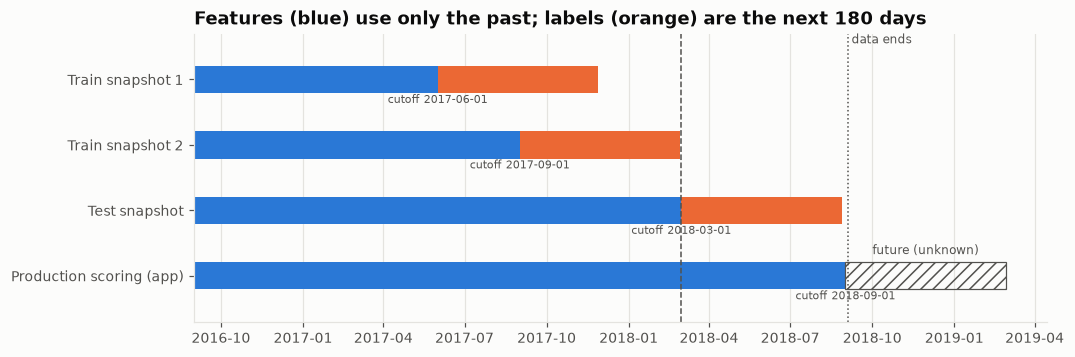

In [2]:
check_no_overlap(TRAIN_CUTOFFS, TEST_CUTOFF, HORIZON)
rows = [
    ("Train snapshot 1", "2017-06-01", "train"),
    ("Train snapshot 2", "2017-09-01", "train"),
    ("Test snapshot", TEST_CUTOFF, "test"),
    ("Production scoring (app)", "2018-09-01", "score"),
]
start = pd.Timestamp("2016-09-01")
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (label, cut, kind) in enumerate(rows[::-1]):
    c = pd.Timestamp(cut)
    ax.barh(i, (c - start).days, left=start, height=0.42, color=SERIES[0])
    if kind == "score":
        ax.barh(i, HORIZON, left=c, height=0.42, color="none", edgecolor=INK_SECONDARY, hatch="///", linewidth=0.8)
        ax.text(c + pd.Timedelta(days=HORIZON / 2), i + 0.33, "future (unknown)", ha="center", fontsize=8, color=INK_SECONDARY)
    else:
        ax.barh(i, HORIZON, left=c, height=0.42, color=SERIES[1])
    ax.text(c, i - 0.36, f"cutoff {cut}", ha="center", fontsize=7.5, color=INK_SECONDARY)
ax.axvline(pd.Timestamp(TEST_CUTOFF), color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.axvline(DATA_END, color=INK_SECONDARY, linestyle=":", linewidth=1)
ax.text(DATA_END, len(rows) - 0.45, " data ends", fontsize=8, color=INK_SECONDARY)
ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_title("Features (blue) use only the past; labels (orange) are the next 180 days")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_ylim(-0.7, len(rows) - 0.3)
save(fig, "churn_timeline")
plt.show()

In [3]:
snap06 = build_snapshot(orders, "2017-06-01", HORIZON)
snap09 = build_snapshot(orders, "2017-09-01", HORIZON)
train = pd.concat([snap06, snap09], ignore_index=True)
test = build_snapshot(orders, TEST_CUTOFF, HORIZON)
sizes = pd.DataFrame(
    {
        "rows": [len(snap06), len(snap09), len(train), len(test)],
        "repeaters": [snap06.label.sum(), snap09.label.sum(), train.label.sum(), test.label.sum()],
    },
    index=["train 2017-06-01", "train 2017-09-01", "train (stacked)", "test 2018-03-01"],
)
sizes["repeat rate"] = (sizes.repeaters / sizes.rows).map("{:.2%}".format)
sizes

,rows,repeaters,repeat rate
train 2017-06-01,11169,176,1.58%
train 2017-09-01,22223,358,1.61%
train (stacked),33392,534,1.60%
test 2018-03-01,56622,669,1.18%


## Model selection on the validation split (train 2017-06 → validate 2017-09)

In [4]:
X06, cats06 = to_lgbm_frame(snap06)
X09, _ = to_lgbm_frame(snap09, cats06)
grid = {
    "lgbm default (15 leaves, 400 trees, lr 0.02)": {},
    "lgbm 7 leaves, 300 trees": {"num_leaves": 7, "n_estimators": 300},
    "lgbm 4 leaves, 200 trees, lr 0.03": {"num_leaves": 4, "n_estimators": 200, "learning_rate": 0.03},
    "lgbm 15 leaves, 150 trees": {"num_leaves": 15, "n_estimators": 150},
}
val = {}
for name, params in grid.items():
    m = make_lgbm(**params).fit(X06, snap06.label)
    val[name] = ranking_metrics(snap09.label, m.predict_proba(X09)[:, 1])
val["logistic regression"] = ranking_metrics(snap09.label, make_logreg().fit(snap06, snap06.label).predict_proba(snap09)[:, 1])
val["recency rule"] = ranking_metrics(snap09.label, recency_rule_score(snap09))
val = pd.DataFrame(val).T.sort_values("pr_auc", ascending=False)
best_name = val.filter(like="lgbm", axis=0).index[0]
best_params = grid[best_name]
print("selected:", best_name)
val.round(4)

selected: lgbm default (15 leaves, 400 trees, lr 0.02)


,roc_auc,pr_auc,base_rate,capture_top10,lift_top10
"lgbm default (15 leaves, 400 trees, lr 0.02)",0.6292,0.0344,0.0161,0.2598,2.5978
"lgbm 7 leaves, 300 trees",0.6186,0.0303,0.0161,0.1983,1.9832
"lgbm 15 leaves, 150 trees",0.6260,0.0295,0.0161,0.1899,1.8994
"lgbm 4 leaves, 200 trees, lr 0.03",0.6049,0.0289,0.0161,0.1676,1.6760
logistic regression,0.5851,0.0269,0.0161,0.1788,1.7877
recency rule,0.5675,0.0202,0.0161,0.1564,1.5642


## Test-set results (2018-03-01 snapshot, used once)

In [5]:
X_train, cats = to_lgbm_frame(train)
X_test, _ = to_lgbm_frame(test, cats)
gbm = make_lgbm(**best_params).fit(X_train, train.label)
logreg = make_logreg().fit(train, train.label)
scores = {
    "Recency rule": recency_rule_score(test),
    "Logistic regression": logreg.predict_proba(test)[:, 1],
    "LightGBM": gbm.predict_proba(X_test)[:, 1],
}
y = test.label.to_numpy()
rng = np.random.default_rng(RANDOM_SEED)
boot_idx = [rng.integers(0, len(y), len(y)) for _ in range(200)]
rows = {}
for name, s in scores.items():
    m = ranking_metrics(y, s)
    pr = [ranking_metrics(y[i], s[i])["pr_auc"] for i in boot_idx]
    roc = [ranking_metrics(y[i], s[i])["roc_auc"] for i in boot_idx]
    m["pr_auc_ci"] = f"{np.quantile(pr, 0.025):.4f}-{np.quantile(pr, 0.975):.4f}"
    m["roc_auc_ci"] = f"{np.quantile(roc, 0.025):.3f}-{np.quantile(roc, 0.975):.3f}"
    rows[name] = m
test_metrics = pd.DataFrame(rows).T[["roc_auc", "roc_auc_ci", "pr_auc", "pr_auc_ci", "base_rate", "capture_top10", "lift_top10"]]
test_metrics

,roc_auc,roc_auc_ci,pr_auc,pr_auc_ci,base_rate,capture_top10,lift_top10
Recency rule,0.567427,0.548-0.589,0.015462,0.0137-0.0173,0.011815,0.153961,1.539611
Logistic regression,0.589032,0.569-0.613,0.028093,0.0210-0.0402,0.011815,0.177877,1.778774
LightGBM,0.580662,0.561-0.602,0.020502,0.0165-0.0267,0.011815,0.19432,1.943199


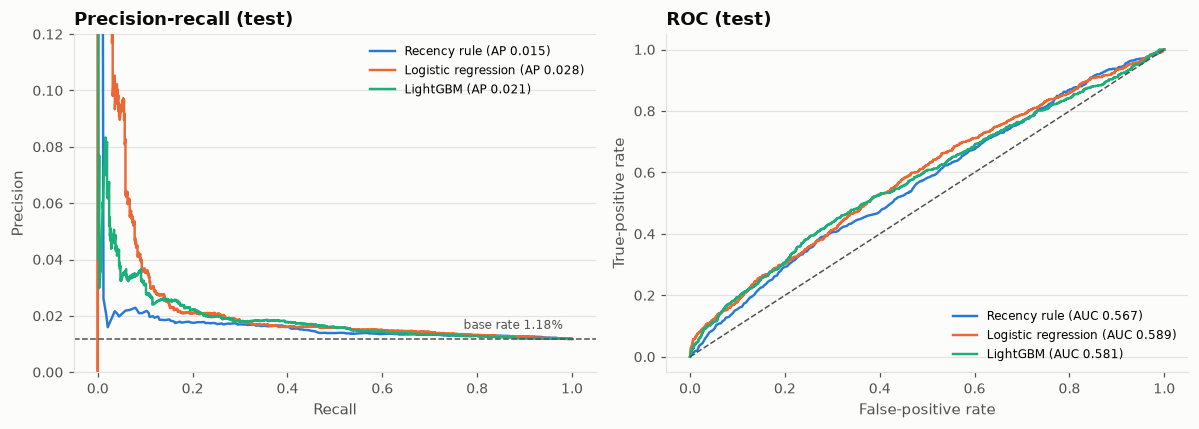

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, (name, s) in enumerate(scores.items()):
    p, r, _ = precision_recall_curve(y, s)
    axes[0].plot(r, p, color=SERIES[i], linewidth=1.6, label=f"{name} (AP {test_metrics.loc[name, 'pr_auc']:.3f})")
    fpr, tpr, _ = roc_curve(y, s)
    axes[1].plot(fpr, tpr, color=SERIES[i], linewidth=1.6, label=f"{name} (AUC {test_metrics.loc[name, 'roc_auc']:.3f})")
axes[0].axhline(y.mean(), color=INK_SECONDARY, linestyle="--", linewidth=1)
axes[0].text(0.98, y.mean() * 1.3, f"base rate {y.mean():.2%}", ha="right", fontsize=8, color=INK_SECONDARY)
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (test)", ylim=(0, 0.12))
axes[1].plot([0, 1], [0, 1], color=INK_SECONDARY, linestyle="--", linewidth=1)
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC (test)")
for a in axes:
    a.legend(fontsize=8, loc="upper right" if a is axes[0] else "lower right")
plt.tight_layout()
save(fig, "churn_pr_roc")
plt.show()

## Lift and cumulative gains

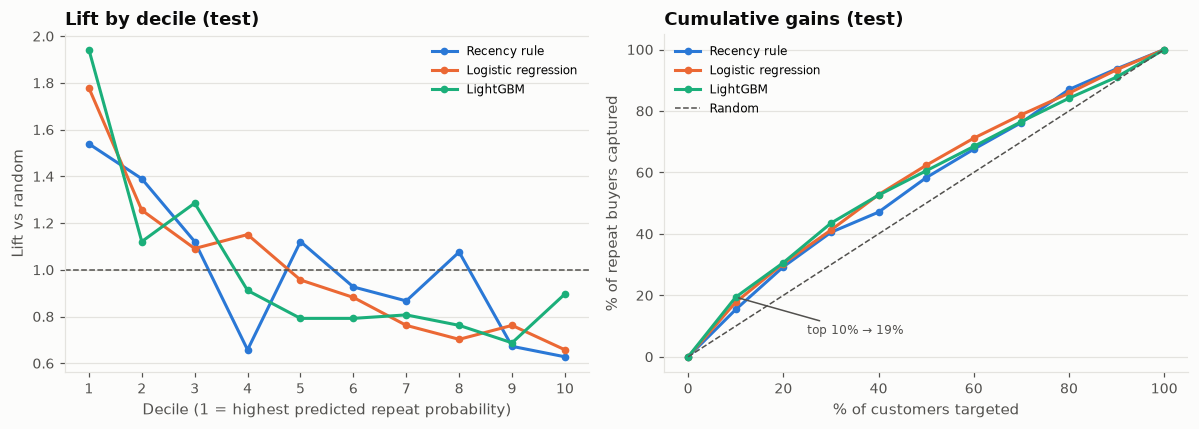

,decile,customers,positives,response_rate,lift,cumulative_population,cumulative_gain
0,1,5663,130,0.0230,1.9429,0.1,0.1943
1,2,5663,75,0.0132,1.1209,0.2,0.3064
2,3,5662,86,0.0152,1.2855,0.3,0.4350
3,4,5662,61,0.0108,0.9118,0.4,0.5262
4,5,5662,53,0.0094,0.7923,0.5,0.6054
5,6,5662,53,0.0094,0.7923,0.6,0.6846
6,7,5662,54,0.0095,0.8072,0.7,0.7653
7,8,5662,51,0.0090,0.7624,0.8,0.8416
8,9,5662,46,0.0081,0.6876,0.9,0.9103
9,10,5662,60,0.0106,0.8969,1.0,1.0000


In [7]:
gains = {name: gains_table(y, s) for name, s in scores.items()}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, (name, g) in enumerate(gains.items()):
    axes[0].plot(g.decile, g.lift, marker="o", markersize=4, color=SERIES[i], label=name)
    axes[1].plot(np.r_[0, g.cumulative_population] * 100, np.r_[0, g.cumulative_gain] * 100, marker="o", markersize=4, color=SERIES[i], label=name)
axes[0].axhline(1, color=INK_SECONDARY, linestyle="--", linewidth=1)
axes[0].set(xlabel="Decile (1 = highest predicted repeat probability)", ylabel="Lift vs random", title="Lift by decile (test)")
axes[0].set_xticks(range(1, 11))
axes[1].plot([0, 100], [0, 100], color=INK_SECONDARY, linestyle="--", linewidth=1, label="Random")
axes[1].set(xlabel="% of customers targeted", ylabel="% of repeat buyers captured", title="Cumulative gains (test)")
g10 = gains["LightGBM"].iloc[0]
axes[1].annotate(f"top 10% → {g10.cumulative_gain:.0%}", (10, g10.cumulative_gain * 100), xytext=(25, g10.cumulative_gain * 100 - 12),
                 fontsize=8, color=INK_SECONDARY, arrowprops=dict(arrowstyle="-", color=INK_SECONDARY))
for a in axes:
    a.legend(fontsize=8)
plt.tight_layout()
save(fig, "churn_lift_gain")
plt.show()
gains["LightGBM"].round(4)

In [8]:
best = test_metrics.loc["LightGBM"]
rule = test_metrics.loc["Recency rule"]
n_test, n_pos = len(y), int(y.sum())
top10 = int(np.ceil(0.1 * n_test))
captured = int(round(best.capture_top10 * n_pos))
sentence = (
    f"Targeting the top 10% of customers ranked by the LightGBM model ({top10:,} of {n_test:,}) captures "
    f"{best.capture_top10:.1%} of the customers who actually purchased again within 180 days ({captured} of {n_pos}), "
    f"a {best.lift_top10:.2f}x lift over random targeting, versus {rule.capture_top10:.1%} for the recency rule."
)
print(sentence)

Targeting the top 10% of customers ranked by the LightGBM model (5,663 of 56,622) captures 19.4% of the customers who actually purchased again within 180 days (130 of 669), a 1.94x lift over random targeting, versus 15.4% for the recency rule.


**Results, read candidly.**
- On the test snapshot (56,622 customers, **669 repeaters, base rate 1.18%**), every model is weak in absolute terms:
  - **LightGBM:** ROC-AUC **0.581** (95% bootstrap CI 0.561–0.602), PR-AUC **0.0205** (0.0165–0.0267);
  - **logistic regression:** ROC-AUC **0.589** (0.569–0.613), PR-AUC **0.0281** (0.0210–0.0402);
  - **recency rule:** ROC-AUC **0.567**, PR-AUC **0.0155**.
- **Headline:** targeting the **top 10%** of customers ranked by LightGBM captures **19.4%** of the customers who actually bought again within 180 days (130 of 669). That is a **1.94x lift** over random targeting, compared with **15.4%** for the recency rule.
- **Model choice is noise-dominated.** LightGBM was selected on validation (PR-AUC 0.034), but on test it falls to 0.020, and logistic regression edges ahead on PR-AUC. The confidence intervals overlap heavily, so we **cannot claim either ML model beats the other**. Both beat the recency rule in the top decile. With only 534 positive examples in training, this is about as much as the data supports.
- The gains curve shows that the useful signal is concentrated in the **top decile** (lift 1.94; deciles 2 and 3: 1.12 and 1.29). Below that, the model ranks customers little better than chance.
- LightGBM stays as the scoring model in the app because it was chosen **before** the test set was opened and gives per-customer SHAP reasons. Logistic regression would be an equally defensible choice.

## What drives the prediction? SHAP
SHAP values are contributions to the **log-odds of repeating**. A negative value pushes the customer toward churn.

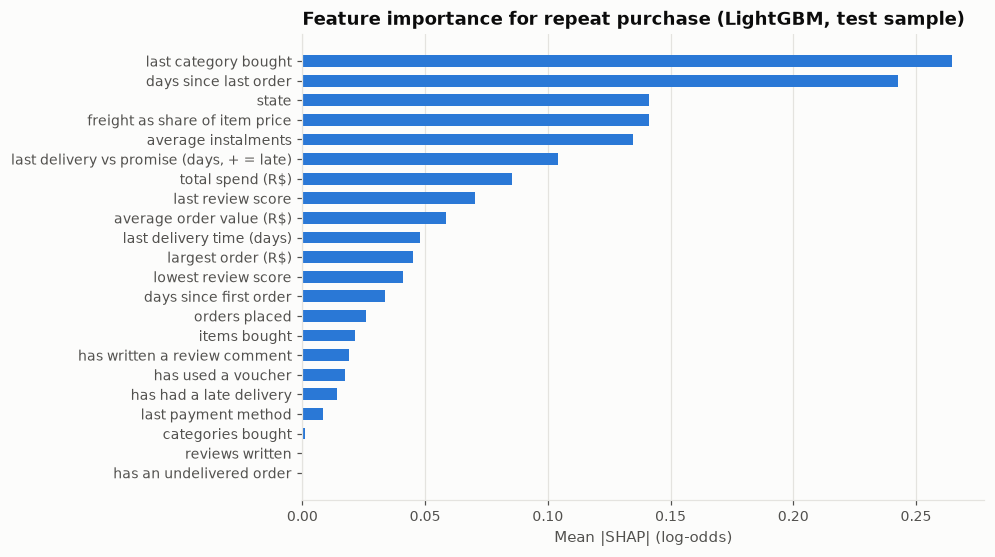

In [9]:
X_sample = X_test.sample(5000, random_state=RANDOM_SEED)
sv = shap_matrix(gbm, X_sample)
importance = pd.Series(np.abs(sv).mean(axis=0), index=X_sample.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([FEATURE_LABELS[c] for c in importance.index], importance.values, color=SERIES[0], height=0.6)
ax.set_xlabel("Mean |SHAP| (log-odds)")
ax.set_title("Feature importance for repeat purchase (LightGBM, test sample)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
save(fig, "churn_shap_importance")
plt.show()

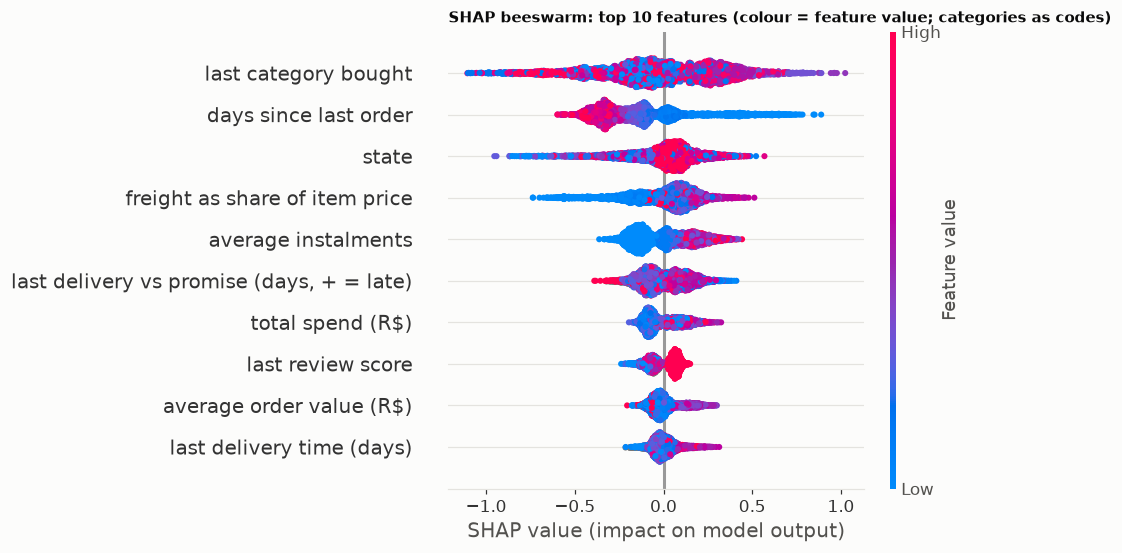

In [10]:
X_plot = X_sample.copy()
for c in CATEGORICAL_FEATURES:
    X_plot[c] = X_plot[c].cat.codes.replace(-1, np.nan)  # colour scale needs numbers
top = importance.index[::-1][:10]
shap.summary_plot(sv[:, [X_sample.columns.get_loc(c) for c in top]], X_plot[top], feature_names=[FEATURE_LABELS[c] for c in top], show=False, plot_size=(9, 5))
plt.title("SHAP beeswarm: top 10 features (colour = feature value; categories as codes)", fontsize=10, loc="left")
save(plt.gcf(), "churn_shap_beeswarm")
plt.show()

In [11]:
# Direction of each numeric effect: rank correlation between a feature's value and its SHAP value.
direction = {}
for f in importance.index[::-1]:
    if f in CATEGORICAL_FEATURES:
        continue
    v = X_sample[f].to_numpy(float)
    ok = ~np.isnan(v)
    direction[FEATURE_LABELS[f]] = pd.Series(sv[ok, X_sample.columns.get_loc(f)]).corr(pd.Series(v[ok]), method="spearman")
direction = pd.Series(direction, name="spearman(value, SHAP)").head(8)
j = X_sample.columns.get_loc("last_delay_days")
late_mask = (X_sample.last_delay_days > 0).to_numpy()
ontime_mask = (X_sample.last_delay_days <= 0).to_numpy()
print(f"Mean SHAP of 'last delivery vs promise': late {sv[late_mask, j].mean():+.3f} vs on time {sv[ontime_mask, j].mean():+.3f} (log-odds)")
direction.round(3)

Mean SHAP of 'last delivery vs promise': late -0.124 vs on time +0.020 (log-odds)


days since last order                       -0.922
freight as share of item price               0.735
average instalments                          0.914
last delivery vs promise (days, + = late)    0.258
total spend (R$)                             0.256
last review score                            0.843
average order value (R$)                     0.289
last delivery time (days)                    0.229
Name: spearman(value, SHAP), dtype: float64

In [12]:
example = X_sample.assign(p_repeat=gbm.predict_proba(X_sample)[:, 1])
example["reasons"] = reason_codes(sv, X_sample, top_n=3)
pd.set_option("display.max_colwidth", 200)
example.sort_values("p_repeat")[["p_repeat", "reasons"]].iloc[[0, len(example) // 2, -1]]

,p_repeat,reasons
11799,0.002131,last category bought = consoles_games (raises churn risk); freight as share of item price = 0.05 (raises churn risk); state = MG (raises churn risk)
15469,0.010813,days since last order = 184 (raises churn risk); last category bought = health_beauty (lowers churn risk); total spend (R$) = 139 (raises churn risk)
33466,0.178216,orders placed = 2 (lowers churn risk); last category bought = sports_leisure (lowers churn risk); days since last order = 25 (lowers churn risk)


**So what (drivers).**
- **Last category bought** and **days since last order** carry the most signal. Recency works as expected: the longer since the last order, the lower the predicted chance of returning (rank correlation between value and SHAP −0.92). That matches the timing seen in EDA Q8.
- **Freight share** and **instalments** push *up* the chance of a repeat when they are high (correlations +0.74 and +0.91). These are correlations inside the model, not causes. A plausible reading is that a high freight-to-price ratio marks cheap, re-buyable items rather than one-off bulky purchases, and that customers who spread payments are more engaged with the platform.
- **Experience matters.** A higher **last review score** raises the predicted chance of returning (+0.84). A **late last delivery** lowers it: mean SHAP is −0.124 for late orders against +0.020 for on-time ones. The review damage from notebook 02 therefore also shows up as fewer repeat purchases.
- **Orders placed** has a low *mean* |SHAP| only because almost everyone has one order. For the few who have two, it is one of the strongest pushes toward returning (see the third example above).

## Limitations and how to use this model
- **The signal is weak.** A 1.18% base rate, 534 training positives, and only transactional data (no visits, email engagement or app usage) cap what any model can do. Results should be quoted with their CIs, as above.
- **Drift.** The 180-day repeat rate fell from 1.6% for the 2017 snapshots to 1.2% for 2018, and behaviour learned on 2017 customers transfers imperfectly.
- **Predicting a repeat is not the same as being persuadable.** The customers most likely to return may return anyway. Before spending on incentives, run an **uplift test**: randomly hold out part of the top-scored customers and measure incremental repeat purchases.
- **Recommended use:** prioritise **cheap** actions (email, app push, free-shipping reminders) at the top 10–20% by score, where the lift is about 1.9x and 1.1x. Do not use the score to justify expensive per-customer offers.

In [13]:
METRICS_DIR.mkdir(parents=True, exist_ok=True)
payload = {
    "horizon_days": HORIZON,
    "train_cutoffs": TRAIN_CUTOFFS,
    "test_cutoff": TEST_CUTOFF,
    "selected_params": best_params,
    "validation": val.reset_index(names="model").to_dict(orient="records"),
    "test": test_metrics.reset_index(names="model").to_dict(orient="records"),
    "test_rows": n_test,
    "test_positives": n_pos,
    "gains_lightgbm": gains["LightGBM"].to_dict(orient="records"),
    "top10_sentence": sentence,
    "shap_importance": importance[::-1].to_dict(),
}
(METRICS_DIR / "churn.json").write_text(json.dumps(payload, indent=2, default=float))
con.close()